# Ballon d'Or — who finishes on the podium?

**Problem.** Every year, a jury of journalists ranks the best ~30 players. We want to predict,
from a player's season (club stats, national-team goals, trophies, market value...), whether he
finishes in the **top 3** of the Ballon d'Or.

**Target:** `top3` (1 if the final rank is 1, 2 or 3, else 0) — a binary classification problem.

**Data:** `data/dataset.csv`, one row per ranked player and per edition (2013–2026).
See `data/README.md` for the sources and the meaning of each column.

This notebook covers the first part of the project:
1. Data overview and cleaning
2. Feature engineering
3. Exploratory data analysis (EDA)
4. Feature importance analysis

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/dataset.csv")
df.shape

(369, 52)

## 2. Data overview

First look at the table: column types, a few rows, summary statistics.

In [3]:
df.head()

,year,rank,name,age,country,position,club,points,trophies_league,trophies_ucl,trophies_uel,trophies_world_cup,trophies_euro,trophies_copa_america,trophies_afcon,trophies_cup,trophies_total,ucl_stage,intl_stage,vote_share,top3,winner,season_based,prev_rank,player_id,apps,minutes,goals,assists,yellow_cards,red_cards,cup_assists,europe_assists,league_assists,cup_goals,europe_goals,league_goals,cup_minutes,europe_minutes,league_minutes,cup_apps,europe_apps,league_apps,ucl_apps,ucl_minutes,ucl_goals,ucl_assists,market_value_eur,intl_goals,intl_major_goals,tm_matched,stats_complete
0,2013,1,Cristiano Ronaldo,28,Portugal,forward,Real Madrid,27.990,0.000,0,0,0,0,0,0,0.000,0.000,4.000,0.000,0.280,1,1,0,2.000,8198,47.000,3948.000,57.000,16.000,10.000,1.000,1.000,2.000,13.000,6.000,14.000,37.000,565.000,900.000,2483.000,6.000,10.000,31.000,10.000,900.000,14.000,2.000,100000000,7.000,0.000,1,1
1,2013,2,Lionel Messi,26,Argentina,forward,Barcelona,24.720,1.000,0,0,0,0,0,0,1.000,2.000,4.000,0.000,0.247,1,0,0,1.000,28003,40.000,3018.000,39.000,12.000,1.000,0.000,1.000,0.000,11.000,2.000,9.000,28.000,353.000,613.000,1917.000,4.000,8.000,26.000,8.000,613.000,9.000,0.000,120000000,3.000,0.000,1,1
2,2013,3,Franck Ribéry,30,France,forward,Bayern Munich,23.360,1.000,1,0,0,0,0,0,1.000,4.000,6.000,0.000,0.234,1,0,0,NaN,22068,39.000,3021.000,15.000,18.000,5.000,0.000,0.000,3.000,15.000,1.000,4.000,10.000,118.000,951.000,1952.000,2.000,11.000,26.000,10.000,831.000,3.000,3.000,42000000,4.000,0.000,1,1
3,2013,4,Zlatan Ibrahimović,32,Sweden,forward,Paris Saint-Germain,5.290,2.000,0,0,0,0,0,0,1.000,3.000,3.000,0.000,0.053,0,0,0,10.000,3455,40.000,3433.000,30.000,13.000,8.000,1.000,0.000,2.000,10.000,0.000,9.000,21.000,0.000,708.000,2635.000,0.000,8.000,31.000,8.000,708.000,9.000,2.000,30000000,6.000,0.000,1,1
4,2013,5,Neymar,21,Brazil,midfielder,Barcelona,3.170,0.000,0,0,0,0,0,0,1.000,2.000,NaN,0.000,0.032,0,0,0,13.000,68290,19.000,1436.000,5.000,11.000,5.000,0.000,0.000,3.000,8.000,0.000,0.000,4.000,0.000,418.000,897.000,0.000,5.000,12.000,5.000,418.000,0.000,3.000,50000000,0.000,0.000,1,1


In [4]:
df.dtypes.value_counts()

float64    32
int64      16
str         4
Name: count, dtype: int64

In [5]:
# Number of ranked players and of podium places per edition
df.groupby("year").agg(players=("name", "size"), podium=("top3", "sum"))

,players,podium
year,,
2013,23,3
2014,23,3
2015,23,3
2016,30,3
2017,30,3
2018,30,3
2019,30,3
2021,30,3
2022,30,3


Each edition has exactly 3 podium players, but not the same number of ranked players
(23 in 2013–2015, about 30 afterwards). The positive class is therefore rare: about 1 row out of 10.

In [6]:
# Missing values: count and share, only for columns that have some
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "share": missing / len(df)}).query("missing > 0") \
  .sort_values("missing", ascending=False)

,missing,share
prev_rank,201,0.545
ucl_stage,76,0.206
intl_stage,21,0.057
trophies_league,10,0.027
trophies_total,10,0.027
goals,5,0.014
apps,5,0.014
minutes,5,0.014
yellow_cards,5,0.014
assists,5,0.014


Three kinds of missing values, each with its own meaning:
- **`prev_rank`** is empty when the player was **not ranked** at the previous edition. This is
  information, not an error: we will turn it into a flag.
- **Club stats** (`apps`, `minutes`, `goals`...) are empty for the 5–6 rows with
  `stats_complete = 0` (league not covered, or known Transfermarkt error).
- **`ucl_stage` / `intl_stage`** are empty when the source did not know the stage reached.

In [7]:
# Summary statistics of the main numeric variables
main_cols = ["age", "minutes", "goals", "assists", "intl_goals", "intl_major_goals",
             "market_value_eur", "trophies_total", "ucl_stage", "intl_stage", "prev_rank"]
df[main_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,369.000,27.496,4.029,17.000,25.000,27.000,30.000,39.000
minutes,364.000,3292.865,710.071,752.000,2824.750,3303.000,3812.000,4770.000
goals,364.000,15.857,13.512,0.000,4.000,13.000,25.000,58.000
assists,364.000,8.613,6.404,0.000,4.000,8.000,12.000,30.000
intl_goals,369.000,2.407,2.886,0.000,0.000,1.000,3.000,19.000
intl_major_goals,369.000,0.835,1.596,0.000,0.000,0.000,1.000,10.000
market_value_eur,369.000,72731707.317,44096883.795,1500000.000,40000000.000,70000000.000,90000000.000,200000000.000
trophies_total,359.000,1.894,1.406,0.000,1.000,2.000,3.000,6.000
ucl_stage,293.000,3.696,1.995,0.000,2.000,4.000,6.000,6.000
intl_stage,348.000,1.928,2.318,0.000,0.000,0.000,4.000,6.000


## 3. Cleaning and feature engineering

### 3.1 Columns we must not use as features (data leakage)

`rank`, `points`, `vote_share` and `winner` are **results of the vote**: they directly give
away the target. Keeping them would produce a perfect but useless model. `player_id`,
`tm_matched`, `name` and `club` are identifiers, not features.

In [8]:
LEAKAGE = ["rank", "points", "vote_share", "winner"]
IDENTIFIERS = ["name", "club", "player_id", "tm_matched"]
TARGET = "top3"

### 3.2 Handling missing values

- `prev_rank` → `ranked_prev` (0/1 flag) and `prev_rank_filled` (31 = "not ranked", i.e. worse
  than the last place).
- Missing trophy counts → 0 (no trophy recorded).
- Missing stages → kept as `NaN` for now (the models step will decide how to impute them).

In [9]:
data = df.copy()

data["ranked_prev"] = data["prev_rank"].notna().astype(int)
data["prev_rank_filled"] = data["prev_rank"].fillna(31)
data["prev_top3"] = (data["prev_rank_filled"] <= 3).astype(int)

trophy_cols = [c for c in data.columns if c.startswith("trophies_")]
data[trophy_cols] = data[trophy_cols].fillna(0)

### 3.3 New features

Raw totals depend on playing time, so we add **per-90-minutes** rates. We also add
"big title" flags, since the vote is known to reward trophies.

In [10]:
data["goal_contrib"] = data["goals"] + data["assists"]            # goals + assists
per90 = 90 / data["minutes"].where(data["minutes"] > 0)          # NaN if no minutes
data["goals_per90"] = data["goals"] * per90
data["goal_contrib_per90"] = data["goal_contrib"] * per90
data["market_value_m"] = data["market_value_eur"] / 1e6          # in millions of euros

data["won_ucl"] = (data["trophies_ucl"] > 0).astype(int)
data["won_major_intl"] = (data[["trophies_world_cup", "trophies_euro", "trophies_copa_america",
                                "trophies_afcon"]].sum(axis=1) > 0).astype(int)
data["won_big_title"] = (data["won_ucl"] | data["won_major_intl"]).astype(int)

### 3.4 Relative features (within an edition)

The Ballon d'Or is a **comparison between the players of the same year**: 30 goals can be
a lot one year and average the next. So for a few key variables we compute the player's
percentile **within his edition** (1.0 = best of the year).

In [11]:
for col in ["goal_contrib", "intl_goals", "market_value_m", "trophies_total"]:
    data[f"{col}_pct_year"] = data.groupby("year")[col].rank(pct=True)

## 4. Target analysis

In [12]:
print(f"Share of podium rows: {data[TARGET].mean():.1%}")
data[TARGET].value_counts()

Share of podium rows: 10.6%


top3
0    330
1     39
Name: count, dtype: int64

The classes are **imbalanced** (≈ 11 % positives). Accuracy will therefore be a misleading
metric: a model predicting "never on the podium" would already reach 89 %. We will use
**ROC AUC** (and check how often the true podium is in the predicted top 3).

## 5. Mean profile: podium vs the rest

Classic first step: compare the **average** (and median) of each variable between the two groups.

In [13]:
compare_cols = ["age", "minutes", "goals", "assists", "goal_contrib", "goal_contrib_per90",
                "intl_goals", "intl_major_goals", "market_value_m", "trophies_total",
                "won_ucl", "won_major_intl", "ucl_stage", "intl_stage", "ranked_prev",
                "prev_top3"]
profile = data.groupby(TARGET)[compare_cols].mean().T
profile.columns = ["rest (top3=0)", "podium (top3=1)"]
profile["ratio"] = profile["podium (top3=1)"] / profile["rest (top3=0)"]
profile.sort_values("ratio", ascending=False)

,rest (top3=0),podium (top3=1),ratio
prev_top3,0.052,0.359,6.968
intl_major_goals,0.694,2.026,2.919
goals,14.062,30.821,2.192
intl_goals,2.148,4.590,2.136
ranked_prev,0.412,0.821,1.991
won_ucl,0.209,0.410,1.962
goal_contrib,22.206,43.333,1.951
won_major_intl,0.124,0.231,1.857
goal_contrib_per90,0.624,1.068,1.710
market_value_m,68.503,108.513,1.584


In [14]:
# Medians are more robust to extreme values (e.g. a 61-goal season)
data.groupby(TARGET)[["goals", "goal_contrib", "intl_goals", "market_value_m", "age"]].median()

,goals,goal_contrib,intl_goals,market_value_m,age
top3,,,,,
0,11.000,22.000,1.000,65.000,27.000
1,32.000,44.000,4.000,100.000,28.000


### Distributions of the key numeric variables

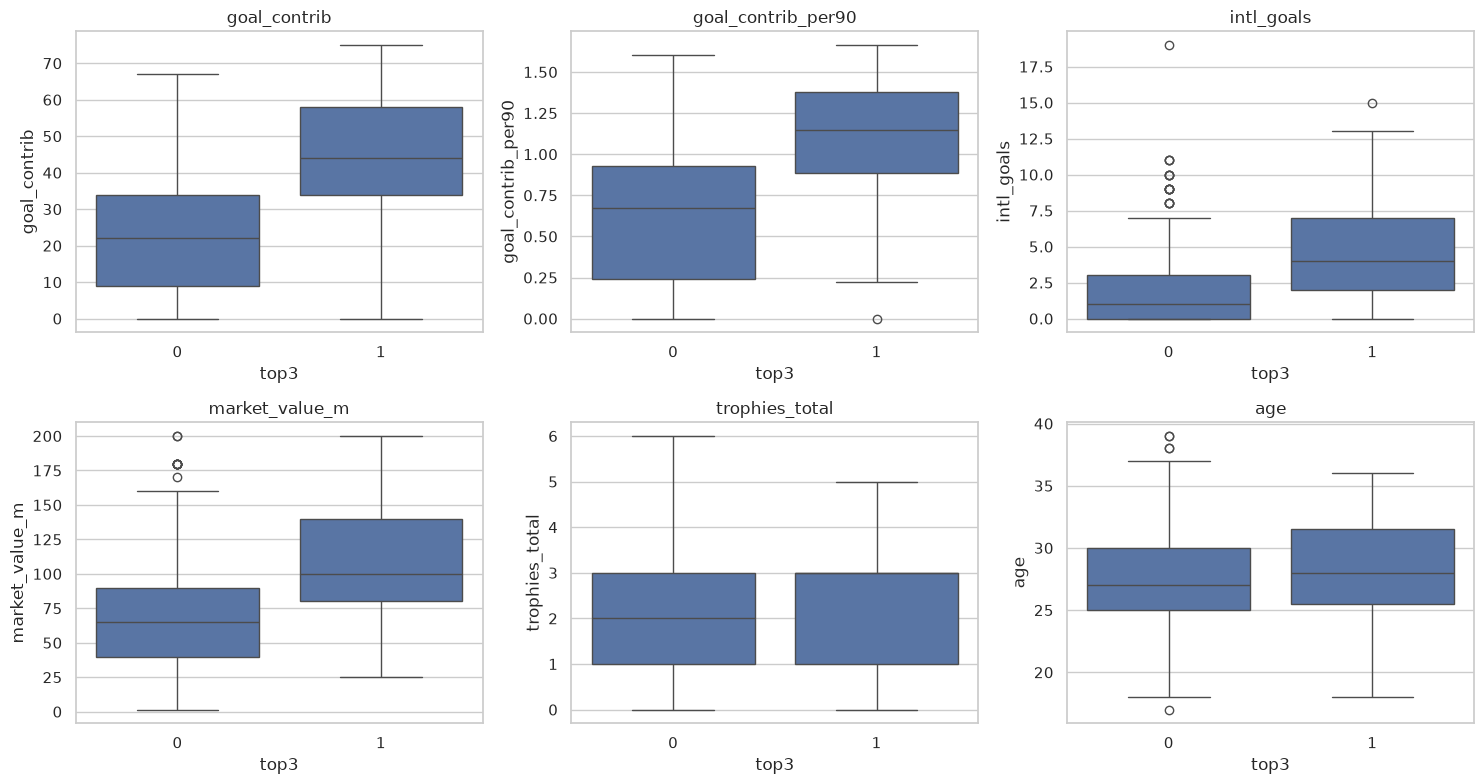

In [15]:
key_num = ["goal_contrib", "goal_contrib_per90", "intl_goals", "market_value_m",
           "trophies_total", "age"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(data=data, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 6. Categorical variables

For a categorical variable, the natural summary is the **podium rate per category**.

In [16]:
def podium_rate(col):
    """Podium rate and number of rows for each value of a column."""
    return (data.groupby(col)[TARGET].agg(podium_rate="mean", n="size")
            .sort_values("podium_rate", ascending=False))

podium_rate("position")

,podium_rate,n
position,,
forward,0.163,178
midfielder,0.071,112
goalkeeper,0.038,26
defender,0.019,53


In [17]:
# Stage reached in the Champions League (0 = absent ... 6 = winner)
podium_rate("ucl_stage").sort_index()

,podium_rate,n
ucl_stage,,
0.000,0.000,35
1.000,0.125,8
2.000,0.029,35
3.000,0.157,51
4.000,0.151,53
5.000,0.038,26
6.000,0.188,85


In [18]:
# Stage reached with the national team in a tournament
podium_rate("intl_stage").sort_index()

,podium_rate,n
intl_stage,,
0.000,0.089,180
1.000,0.154,13
2.000,0.037,27
3.000,0.032,31
4.000,0.083,24
5.000,0.174,23
6.000,0.180,50


In [19]:
# Big titles: Champions League and/or major national-team trophy
podium_rate(["won_ucl", "won_major_intl"])

podium_rate    n
won_ucl won_major_intl                  
1       0                     0.189   74
        1                     0.182   11
0       1                     0.179   39
        0                     0.065  245

In [20]:
# Clubs with at least 10 ranked players
club_rates = data.groupby("club")[TARGET].agg(podium_rate="mean", n="size")
club_rates.query("n >= 10").sort_values("podium_rate", ascending=False)

,podium_rate,n
club,,
Barcelona,0.243,37
Atlético Madrid,0.182,11
Real Madrid,0.172,58
Juventus,0.133,15
Paris Saint-Germain,0.128,39
Bayern Munich,0.114,35
Liverpool,0.080,25
Manchester City,0.077,39
Chelsea,0.056,18


## 7. Feature importance

### 7.1 Correlation with the target

The correlation between a numeric feature and a 0/1 target (point-biserial correlation) tells
how much the feature moves with the podium. It only captures **linear** relationships.

In [21]:
features = [c for c in data.select_dtypes("number").columns
            if c not in LEAKAGE + IDENTIFIERS + [TARGET, "year", "season_based", "stats_complete"]]

corr = data[features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.tail(15)

ranked_prev               0.252
intl_major_goals          0.257
intl_goals                0.260
market_value_m            0.279
market_value_eur          0.279
market_value_m_pct_year   0.280
goal_contrib_per90        0.316
goal_contrib_pct_year     0.318
goals_per90               0.327
prev_top3                 0.341
league_goals              0.344
goal_contrib              0.378
goals                     0.384
ucl_goals                 0.416
europe_goals              0.418
Name: top3, dtype: float64

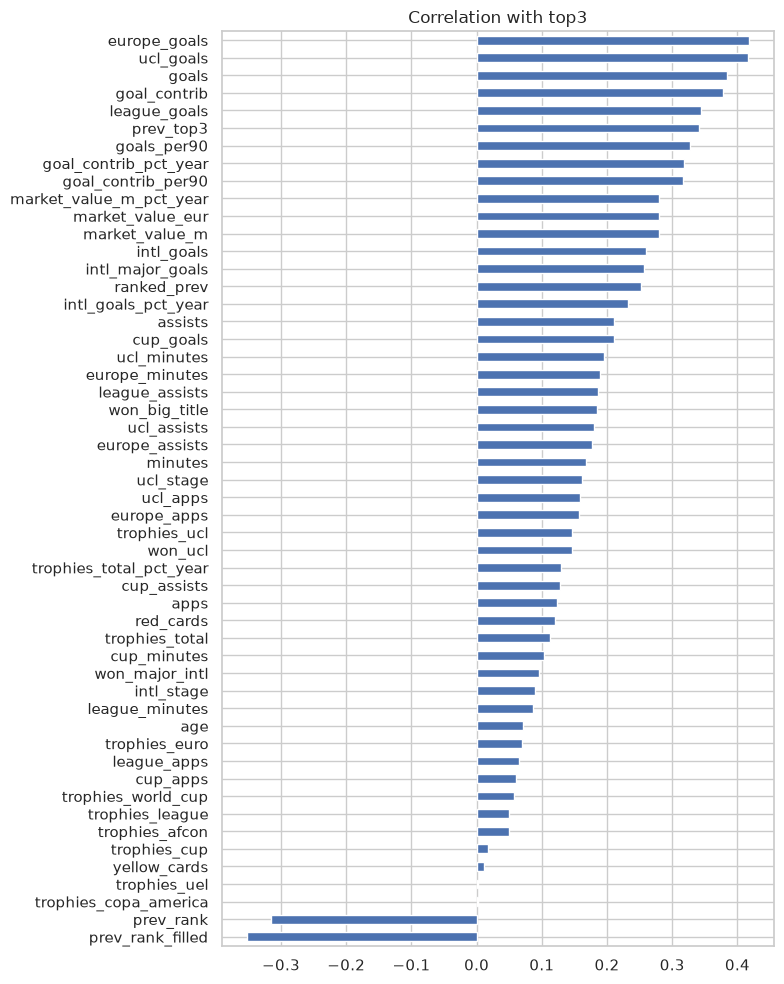

In [22]:
fig, ax = plt.subplots(figsize=(8, 10))
corr.plot.barh(ax=ax)
ax.set_title("Correlation with top3")
plt.tight_layout()
plt.show()

### 7.2 Mutual information

Mutual information measures any kind of dependence (not only linear). It needs a table
without missing values, so we fill the gaps with the median, just for this analysis.

In [23]:
X = data[features].fillna(data[features].median())
mi = mutual_info_classif(X, data[TARGET], random_state=42)
mi = pd.Series(mi, index=features).sort_values(ascending=False)
mi.head(15)

prev_rank_filled          0.091
prev_rank                 0.084
goals                     0.080
ucl_goals                 0.074
europe_goals              0.072
goal_contrib_per90        0.067
goal_contrib              0.064
market_value_m_pct_year   0.063
goal_contrib_pct_year     0.062
league_goals              0.052
goals_per90               0.049
league_assists            0.047
minutes                   0.046
cup_minutes               0.032
ucl_stage                 0.031
dtype: float64

### 7.3 Correlations between the strongest features

Many features say almost the same thing (`goals`, `league_goals`, `goal_contrib`...). The
heatmap shows these redundancies, which matter for the linear model.

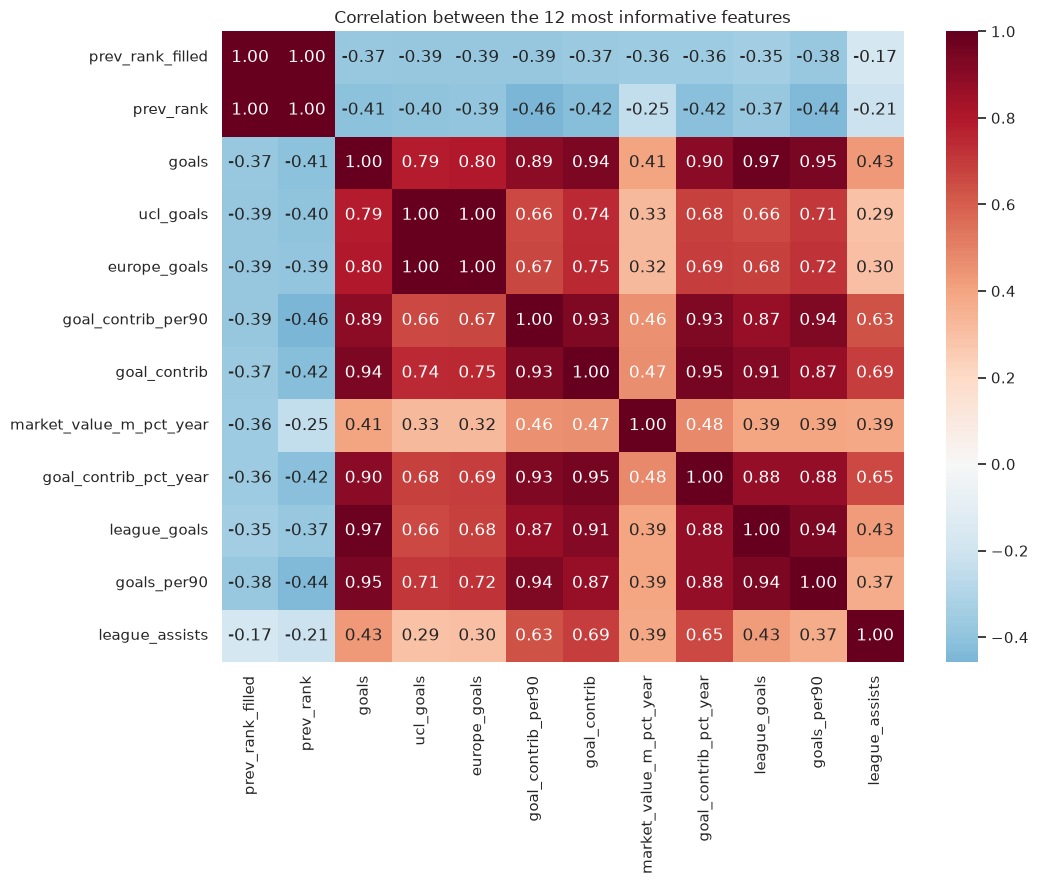

In [24]:
top_features = mi.head(12).index.tolist()
plt.figure(figsize=(11, 9))
sns.heatmap(data[top_features].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between the 12 most informative features")
plt.tight_layout()
plt.show()

## 8. Focus: the winners and the 2026 edition

In [25]:
winner_cols = ["year", "name", "position", "club", "goal_contrib", "intl_goals",
               "market_value_m", "won_ucl", "won_major_intl", "prev_rank"]
data.loc[data["winner"] == 1, winner_cols]

,year,name,position,club,goal_contrib,intl_goals,market_value_m,won_ucl,won_major_intl,prev_rank
0,2013,Cristiano Ronaldo,forward,Real Madrid,73.000,7.000,100.000,0,0,2.000
23,2014,Cristiano Ronaldo,forward,Real Madrid,75.000,3.000,120.000,1,0,1.000
46,2015,Lionel Messi,forward,Barcelona,73.000,1.000,120.000,1,0,2.000
69,2016,Cristiano Ronaldo,forward,Real Madrid,46.000,8.000,110.000,1,1,2.000
99,2017,Cristiano Ronaldo,forward,Real Madrid,42.000,8.000,100.000,1,0,1.000
129,2018,Luka Modrić,midfielder,Real Madrid,9.000,2.000,25.000,1,0,5.000
159,2019,Lionel Messi,forward,Barcelona,49.000,1.000,150.000,0,0,5.000
189,2021,Lionel Messi,forward,Paris Saint-Germain,40.000,9.000,80.000,0,1,1.000
219,2022,Karim Benzema,forward,Real Madrid,59.000,6.000,30.000,1,0,4.000
249,2023,Lionel Messi,forward,Inter Miami,40.000,7.000,35.000,0,1,NaN


In [26]:
# 2026 podium compared with the rest of the 2026 top 10
cols_2026 = ["rank", "name", "goal_contrib", "intl_goals", "intl_major_goals",
             "market_value_m", "trophies_total", "ucl_stage", "intl_stage", "prev_rank"]
data.query("year == 2026").sort_values("rank")[cols_2026].head(10)

,rank,name,goal_contrib,intl_goals,intl_major_goals,market_value_m,trophies_total,ucl_stage,intl_stage,prev_rank
339,1,Harry Kane,65.000,11.000,6.000,60.000,3.000,4.000,4.000,13.000
340,2,Kylian Mbappé,49.000,15.000,10.000,180.000,0.000,3.000,4.000,7.000
341,3,Lamine Yamal,42.000,1.000,1.000,200.000,3.000,3.000,6.000,2.000
342,4,Rodri,2.000,0.000,0.000,50.000,3.000,NaN,6.000,NaN
343,5,Lionel Messi,NaN,10.000,8.000,15.000,1.000,NaN,5.000,NaN
344,6,Khvicha Kvaratskhelia,28.000,2.000,0.000,140.000,5.000,6.000,0.000,12.000
345,7,Ousmane Dembélé,28.000,6.000,6.000,100.000,5.000,6.000,4.000,1.000
346,8,Erling Haaland,46.000,19.000,7.000,200.000,2.000,2.000,3.000,26.000
347,9,Michael Olise,52.000,2.000,0.000,150.000,3.000,4.000,4.000,30.000
348,10,Fabián Ruiz,7.000,1.000,1.000,30.000,6.000,6.000,6.000,24.000


## 9. Summary of the EDA

**Target.** 39 podium rows out of 369 (≈ 11 %): imbalanced classes → ROC AUC rather than accuracy.

**What separates the podium from the rest** (means and medians, section 5):
- **Past reputation is the strongest single signal.** 36 % of podium players were already on
  the podium the year before, against 5 % for the others. The jury has a memory.
- **Scoring, above all in Europe.** Median of 32 goals for podium players against 11. Goals in
  European competitions (`europe_goals`, `ucl_goals`) are the most correlated stats (≈ 0.42):
  big nights in the Champions League weigh more than league goals.
- **National-team tournaments.** Podium players score almost 3 times more goals in major
  tournaments (`intl_major_goals`) — confirming that national-team stats must be kept.
- **Big titles.** Winning the Champions League or a major national trophy triples the podium
  rate (≈ 18 % vs 6.5 %).
- **Market value** helps, moderately (median 100 M€ vs 65 M€). **Age** barely matters.

**Categorical variables** (section 6):
- **Position matters a lot**: 16 % podium rate for forwards, 7 % for midfielders, 2–4 % for
  defenders and goalkeepers.
- **Stages are not monotonic**: reaching the Champions League final and **losing** it (stage 5)
  gives a lower podium rate than a semi-final. Treat stages as categories, not as numbers.

**Feature importance** (section 7): correlation and mutual information agree on the top
features — previous rank, (European) goals, goal contributions per 90, market value. Many stat
columns are highly redundant: the linear model will need regularisation or a reduced set.

**Limits to keep in mind**
- Some winners are not explained by statistics: **Modrić 2018** (9 goals + assists) or
  **Rodri 2024** won through their role and trophies. A stats-based model will miss them.
- Small dataset (369 rows, 39 positives): use a **time-based split** (train on past editions,
  validate on recent ones) and keep the model simple.